# Georgia Election Analysis

## Import Libraries

In [67]:
from matplotlib.patches import Patch
import pandas as pd
import matplotlib.pyplot as plt
import statistics

data = pd.read_csv("senate.csv")
results_data = pd.read_csv("georgia_results_index.csv")
backtest_data_2022 = pd.read_csv("georgia_2022_polling_backtest.csv")
backtest_data_2020 = pd.read_csv("georgia_2020_polling_backtest.csv")
backtest_data_2016 = pd.read_csv("georgia_2016_polling_backtest.csv")
backtest_data_2014 = pd.read_csv("georgia_2014_polling_backtest.csv")

## Historical data results from the 2022 Georgia Senate Race: Democrat, Republican, and Third Party

  Candidate Party    Votes    Percent
0   Warnock   DEM  1820633  51.403055
1    Walker   REP  1721244  48.596945


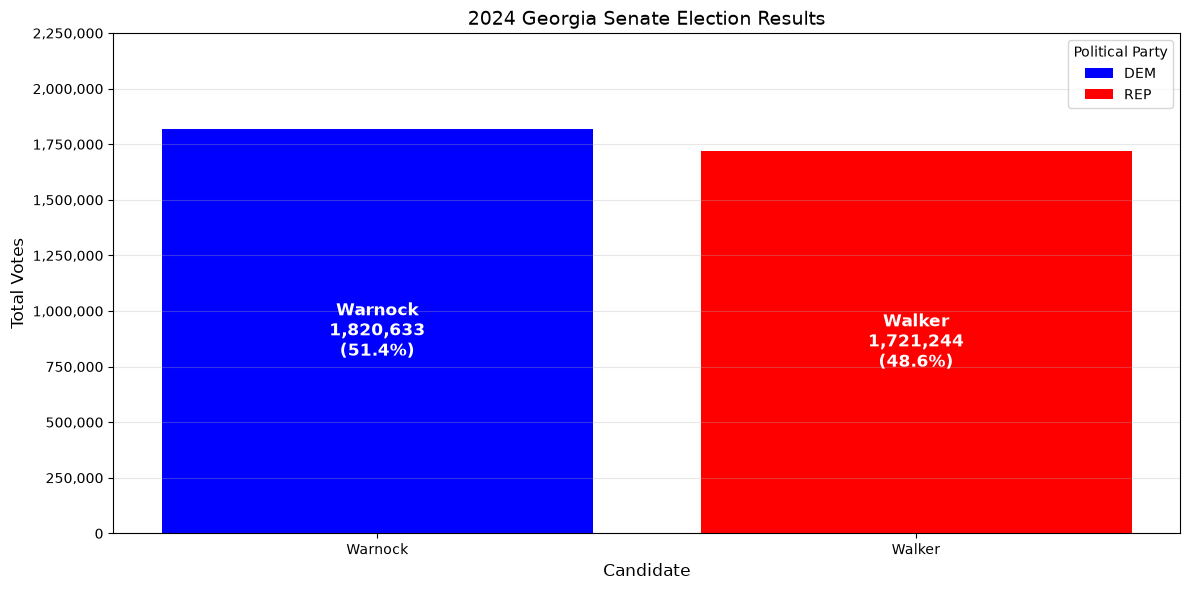

In [ ]:
# ---------------------------------------------------------------
# 1. RAW DATA
# ---------------------------------------------------------------
# Votes from the 2022 Georgia Senate election. These are the official results 
# from the Georgia Secretary of State.
votes = {
    "Warnock":      {"party": "DEM",  "votes": 1820633},
    "Walker":       {"party": "REP",  "votes": 1721244},
    "Third Party":  {"party": "NONE", "votes":  0},
}

# Generate the total votes for percentage calculations.
total_votes = sum(c["votes"] for c in votes.values())

# ---------------------------------------------------------------
# 2. DATAFRAME
# ---------------------------------------------------------------
# Create a DataFrame from the raw data, calculating the percentage of votes for 
# each candidate.
data_2024 = pd.DataFrame([
    {
        "Candidate": name,
        "Party":     info["party"],
        "Votes":     info["votes"],
        "Percent":   info["votes"] / total_votes * 100,
    }
    for name, info in votes.items()
])

# Sort highest-to-lowest so the chart reads left-to-right by size.
data_2024 = data_2024.sort_values("Votes", ascending=False).reset_index(drop=True)

# Drop candidates who received no votes — nothing to draw.
data_2024 = data_2024[data_2024["Votes"] > 0].reset_index(drop=True)

print(data_2024)

# ---------------------------------------------------------------
# 3. DISPLAY SETTINGS
# ---------------------------------------------------------------
# One place to control how each party looks. "label" is what the
# legend and chart show; "color" is the bar fill.
PARTY_STYLE = {
    "DEM":  {"color": "blue",  "label": "DEM"},
    "REP":  {"color": "red",   "label": "REP"},
    "NONE": {"color": "green", "label": "THIRD"},
}

def style_for(party):
    """Return color + label for a party, defaulting to gray/unknown."""
    return PARTY_STYLE.get(party, {"color": "gray", "label": party})

# ---------------------------------------------------------------
# 4. DRAW THE BARS
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6))

# x-positions are 0, 1, 2 — computed once so bars and labels
# can never drift out of sync.
x_positions = range(len(data_2024))

for x, row in zip(x_positions, data_2024.itertuples()):
    ax.bar(x, row.Votes, color=style_for(row.Party)["color"])

# ---------------------------------------------------------------
# 5. LABEL THE BARS
# ---------------------------------------------------------------
for x, row in zip(x_positions, data_2024.itertuples()):
    votes_fmt = f"{row.Votes:,}"
    pct_fmt = f"({row.Percent:.1f}%)"

    # Small bars get only the percentage; big bars get name + votes + %.
    if row.Party == "NONE":
        text = pct_fmt
    else:
        text = f"{row.Candidate}\n{votes_fmt}\n{pct_fmt}"

    ax.text(x, row.Votes / 2, text,
            ha="center", va="center",
            fontsize=12, fontweight="bold", color="white")

# ---------------------------------------------------------------
# 6. AXES, TITLE, LEGEND
# ---------------------------------------------------------------
# Tell matplotlib the tick labels are the candidate names.
ax.set_xticks(list(x_positions))
ax.set_xticklabels(data_2024["Candidate"])

ax.set_xlabel("Candidate", fontsize=12)
ax.set_ylabel("Total Votes", fontsize=12)
ax.set_title("2024 Georgia Senate Election Results", fontsize=14)

# Comma formatting on the y-axis, e.g. 1,500,000
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.grid(axis="y", alpha=0.3)
ax.set_ylim(0, 2_250_000)

# Legend: one swatch per party, using the same style table.
# dict.fromkeys(...) removes duplicates while keeping order.
legend_elements = [
    Patch(facecolor=style_for(p)["color"], label=style_for(p)["label"])
    for p in dict.fromkeys(data_2024["Party"])
]
ax.legend(handles=legend_elements, title="Political Party", loc="upper right")

plt.tight_layout()
plt.show()

## Data Results of Current Week's Polls, by Candidate

           Answer Political Party  Sample Size
0          Ossoff             DEM      62234.0
1  Collins (Mike)             REP      51896.0
2    Someone else            NONE      40191.0
3          Dooley             REP      27356.0
4  Carter (Buddy)             REP      25181.0


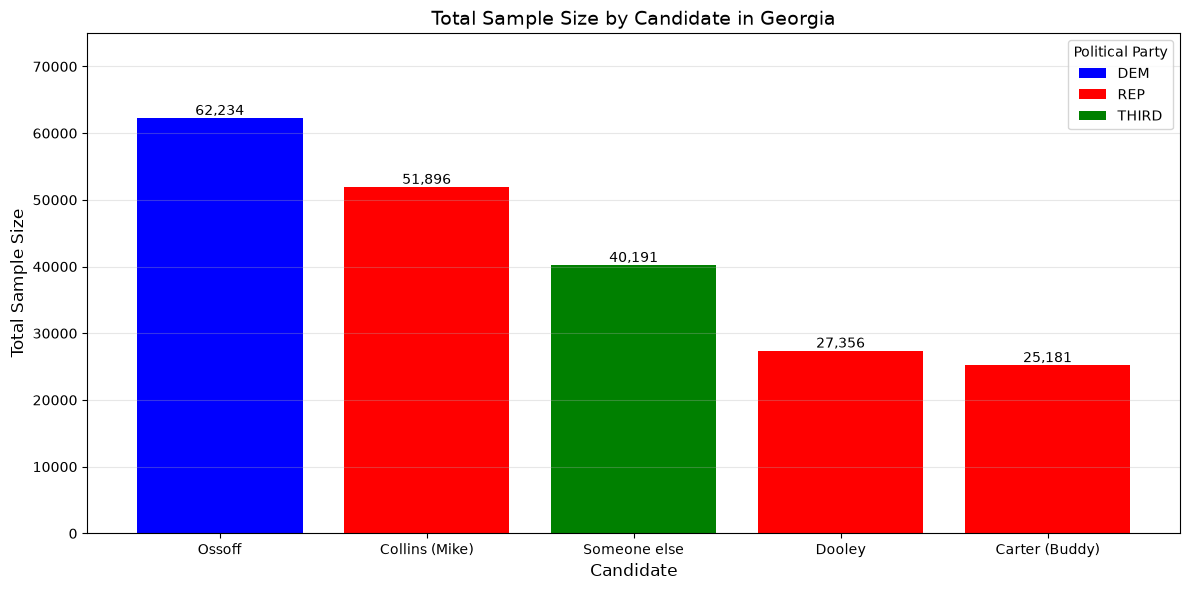

In [ ]:
# =====================================================================
# STAGE 1 — LOAD AND CLEAN THE CSV DATA
# =====================================================================

# Rename columns to friendlier labels (Title Case, readable in output).
data = data.rename(columns={
    "state":       "State",
    "sample_size": "Sample Size",
    "party":       "Political Party",
    "answer":      "Answer",
})


# Keep only Georgia rows with a recognized party.
GEORGIA = "GA"
KEEP_PARTIES = ["DEM", "REP", "NONE"]
data = data[
    (data["State"] == GEORGIA)
    & (data["Political Party"].isin(KEEP_PARTIES))
]

# Drop "non-answers" — these aren't real candidates.
NON_ANSWERS = ["Don't know", "Refused", "No opinion"]
data = data[~data["Answer"].isin(NON_ANSWERS)]

# Remove exact duplicate rows.
data = data.drop_duplicates()

# =====================================================================
# STAGE 2 — AGGREGATE: top 5 candidates by total sample size
# =====================================================================

df_top5 = (
    data
    .groupby(["Answer", "Political Party"])["Sample Size"]
    .sum()
    .reset_index()
    .sort_values("Sample Size", ascending=False)
    .head(5)
    .reset_index(drop=True)     # clean 0-based index for plotting
)

print(df_top5)

# Rename the two columns the plot needs, so row["Votes"] / row["Party"]
# reads naturally in the drawing loops below.
df_top5 = df_top5.rename(columns={
    "Political Party": "Party",
    "Sample Size":     "Votes",
})

# =====================================================================
# STAGE 3 — DISPLAY SETTINGS (one place for names and colors)
# =====================================================================

PARTY_STYLE = {
    "DEM":  {"color": "blue",  "label": "DEM"},
    "REP":  {"color": "red",   "label": "REP"},
    "NONE": {"color": "green", "label": "THIRD"},
}

def style_for(party):
    """Return the color and label for a party, defaulting to gray."""
    return PARTY_STYLE.get(party, {"color": "gray", "label": party})

# =====================================================================
# STAGE 4 — DRAW THE BAR CHART
# =====================================================================

fig, ax = plt.subplots(figsize=(12, 6))

# Positions 0, 1, 2, ... shared by bars and labels so they never drift.
x_positions = range(len(df_top5))

# Bars: one per row, colored by party
for x in x_positions:
    row = df_top5.iloc[x]
    ax.bar(x, row["Votes"], color=style_for(row["Party"])["color"])

# Value labels: placed just above each bar
for x in x_positions:
    row = df_top5.iloc[x]
    ax.text(x, row["Votes"], f"{int(row['Votes']):,}",
            ha="center", va="bottom", fontsize=10)

# Axes, title, grid
ax.set_xticks(list(x_positions))
ax.set_xticklabels(df_top5["Answer"], rotation=0)
ax.set_xlabel("Candidate", fontsize=12)
ax.set_ylabel("Total Sample Size", fontsize=12)
ax.set_title("Total Sample Size by Candidate in Georgia", fontsize=14)
ax.set_ylim(0, 75_000)
ax.grid(axis="y", alpha=0.3)

# Legend: one swatch per party, generated from PARTY_STYLE
legend_elements = [
    Patch(facecolor=style_for(p)["color"], label=style_for(p)["label"])
    for p in dict.fromkeys(df_top5["Party"])
]
ax.legend(handles=legend_elements, title="Political Party", loc="upper right")

plt.tight_layout()
plt.show()

## Data Results of Week's Polls, by Political Party

  Party     Votes
0   REP  104433.0
1   DEM   62234.0
2  NONE   40191.0


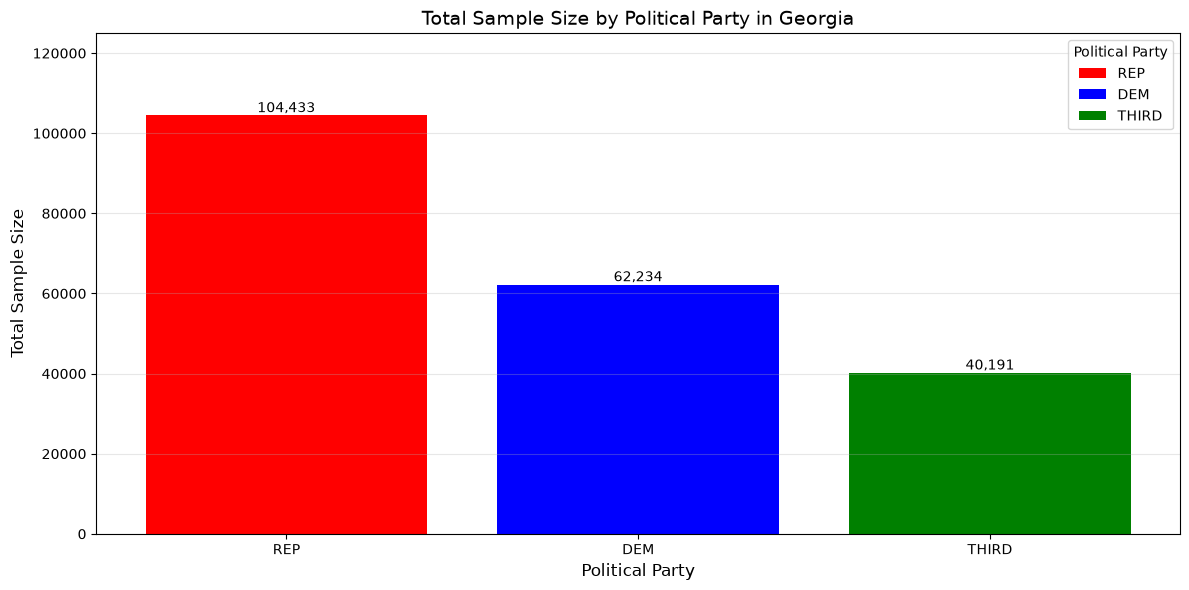

In [ ]:
# =====================================================================
# STAGE 1 — AGGREGATE: total sample size per party
# =====================================================================

# df_aggregated holds the top-5 candidates, one row per (candidate, party).
# Summing "Sample Size" grouped by party combines those candidates into
# one total per political party.
# Previous block — keep original column names in df_aggregated
df_aggregated = (
    data
    .groupby(["Answer", "Political Party"])["Sample Size"]
    .sum()
    .reset_index()
    .sort_values("Sample Size", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

party_totals = (
    df_aggregated
    .groupby("Political Party")["Sample Size"]
    .sum()
    .reset_index()
    .sort_values("Sample Size", ascending=False)
    .reset_index(drop=True)
)

# Friendly names for the plotting loops.
party_totals = party_totals.rename(columns={
    "Political Party": "Party",
    "Sample Size":     "Votes",
})

print(party_totals)

# =====================================================================
# STAGE 2 — DISPLAY SETTINGS (one place for names and colors)
# =====================================================================

PARTY_STYLE = {
    "DEM":  {"color": "blue",  "label": "DEM"},
    "REP":  {"color": "red",   "label": "REP"},
    "NONE": {"color": "green", "label": "THIRD"},
}

def style_for(party):
    """Return the color and label for a party, defaulting to gray."""
    return PARTY_STYLE.get(party, {"color": "gray", "label": party})

# =====================================================================
# STAGE 3 — DRAW THE BAR CHART
# =====================================================================

fig, ax = plt.subplots(figsize=(12, 6))

# Positions 0, 1, 2 shared by bars and labels so they never drift.
x_positions = range(len(party_totals))

# Bars: one per party, colored by party
for x in x_positions:
    row = party_totals.iloc[x]
    ax.bar(x, row["Votes"], color=style_for(row["Party"])["color"])

# Value labels: placed just above each bar
for x in x_positions:
    row = party_totals.iloc[x]
    votes = row["Votes"]
    ax.text(x, votes, f"{int(votes):,}", ha="center", va="bottom", fontsize=10)

# Axes, title, grid
# The x-axis shows the *display name* of each party ("Third Party" not "NONE").
ax.set_xticks(list(x_positions))
ax.set_xticklabels(
    [style_for(p)["label"] for p in party_totals["Party"]],
    rotation=0,
)
ax.set_xlabel("Political Party", fontsize=12)
ax.set_ylabel("Total Sample Size", fontsize=12)
ax.set_title("Total Sample Size by Political Party in Georgia", fontsize=14)
ax.set_ylim(0, 125_000)
ax.grid(axis="y", alpha=0.3)

# Legend: one swatch per party, generated from PARTY_STYLE
legend_elements = [
    Patch(facecolor=style_for(p)["color"], label=style_for(p)["label"])
    for p in party_totals["Party"]
]
ax.legend(handles=legend_elements, title="Political Party", loc="upper right")

plt.tight_layout()
plt.show()

## Calculating median error rate from backtest analysis

In [71]:
# =====================================================================
# STAGE 1 — RAW BACKTEST VALUES (row/column lookups made explicit)
# =====================================================================
# Each election year maps to the row that holds that party's
# median polling error in that year's backtest table.
# The column is index 1 (the second column) in every table.
ERROR_COLUMN = 1

BACKTEST_TABLES = {
    2024: (backtest_data_2022, {"DEM": 13, "REP": 14,}),
    2020: (backtest_data_2020, {"DEM": 13, "REP": 14,}),
    2018: (backtest_data_2016, {"DEM": 13, "REP": 14, "NONE": 15}),
    2014: (backtest_data_2014, {"DEM": 13, "REP": 14, "NONE": 15}),
}

# Pull the error value for one party in one year.
def error_for(table, row_index):
    return float(table.iloc[row_index, ERROR_COLUMN])

# =====================================================================
# STAGE 2 — COLLECT AND MEDIAN
# =====================================================================
# Build {"DEM": [...], "REP": [...], "NONE": [...]} in one pass,
# then take the median of each list.
errors_by_party = {"DEM": [], "REP": [], "NONE": []}

for year, (table, rows) in BACKTEST_TABLES.items():
    for party, row_index in rows.items():
        errors_by_party[party].append(error_for(table, row_index))

median_error_margins = {
    party: statistics.median(values)
    for party, values in errors_by_party.items()
}

print("Median error margins by party:", median_error_margins)

Median error margins by party: {'DEM': 0.1242818775, 'REP': 0.0037629610000000004, 'NONE': -3.0325814535}


## Consolidated data from historical results, polling data, backtest analysis, and volatility index

Predicted percentages by party: {'DEM': np.float64(36.480677451657925), 'REP': np.float64(49.9188333238499), 'NONE': np.float64(13.600489224492161)}


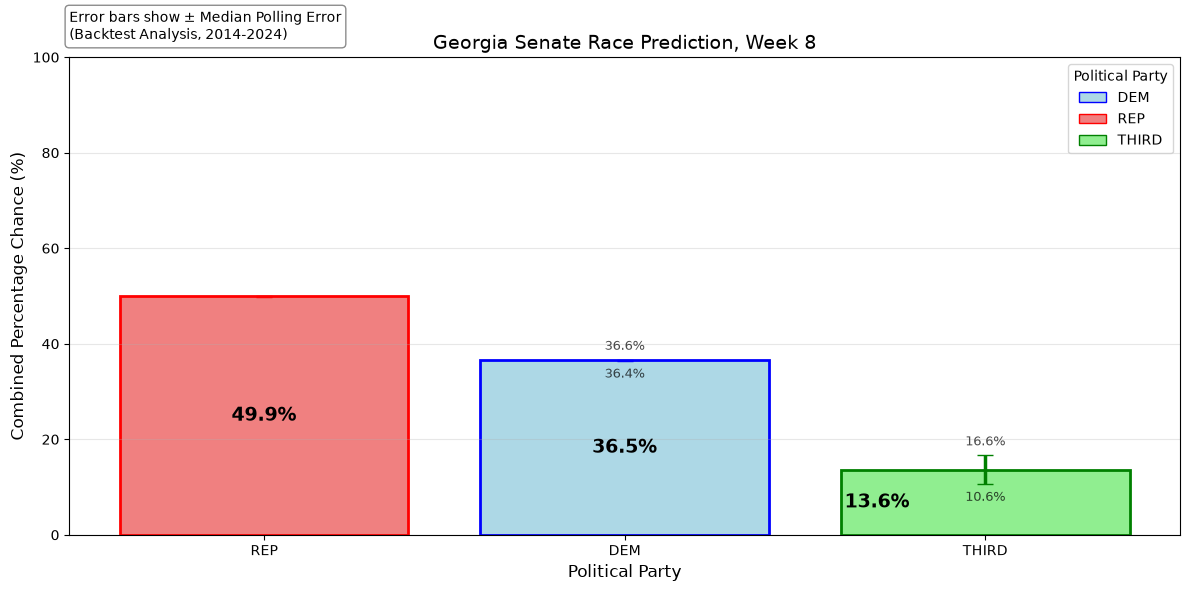

In [ ]:
# =====================================================================
# STAGE 1 — WEIGHTS (all tunable numbers in one place)
# =====================================================================

WEEK = 8                         # update manually each week
POLL_WEIGHT       = 0.70         # weight given to current polling
HISTORICAL_WEIGHT = 0.30         # weight given to 2024 actual results
assert POLL_WEIGHT + HISTORICAL_WEIGHT == 1.0

# =====================================================================
# STAGE 2 — POLLING PERCENTAGES (from party_totals table)
# =====================================================================

# party_totals has columns "Party" and "Votes" (renamed earlier).
total_polls = party_totals["Votes"].sum()

poll_percent = {
    row["Party"]: row["Votes"] / total_polls * 100
    for _, row in party_totals.iterrows()
}

# =====================================================================
# STAGE 3 — HISTORICAL PERCENTAGES (from the 2024 election DataFrame)
# =====================================================================

# data_2024 has columns "Candidate", "Party", "Votes", "Percent".
# Build {"DEM": <percent>, "REP": <percent>, "NONE": <percent>}.
historical_percent = {
    row["Party"]: row["Percent"]
    for _, row in data_2024.iterrows()
}

# =====================================================================
# STAGE 4 — COMBINE INTO PREDICTED PERCENTAGES
# =====================================================================

predicted = {
    party: (poll_percent.get(party, 0) * POLL_WEIGHT)
         + (historical_percent.get(party, 0) * HISTORICAL_WEIGHT)
    for party in ["DEM", "REP", "NONE"]
}

print("Predicted percentages by party:", predicted)

# Build a sorted DataFrame for the plot.
combined_df = (
    pd.DataFrame({
        "Party":     list(predicted.keys()),
        "Predicted": [round(v, 1) for v in predicted.values()],
    })
    .sort_values("Predicted", ascending=False)
    .reset_index(drop=True)
)

# =====================================================================
# STAGE 5 — DISPLAY SETTINGS
# =====================================================================

PARTY_STYLE = {
    "DEM":  {"fill": "lightblue",  "edge": "blue",  "label": "DEM",         "label_dx": 0.0},
    "REP":  {"fill": "lightcoral", "edge": "red",   "label": "REP",         "label_dx": 0.0},
    "NONE": {"fill": "lightgreen", "edge": "green", "label": "THIRD", "label_dx": -0.3},
}

def style_for(party):
    return PARTY_STYLE.get(
        party,
        {"fill": "lightgray", "edge": "gray", "label": party},
    )

# =====================================================================
# STAGE 6 — DRAW THE BAR CHART
# =====================================================================

fig, ax = plt.subplots(figsize=(12, 6))

x_positions = range(len(combined_df))

# Bars with error bars
for x in x_positions:
    row = combined_df.iloc[x]
    party = row["Party"]
    percent = row["Predicted"]
    style = style_for(party)
    error = abs(median_error_margins.get(row["Party"], 0))

    ax.bar(
        x, percent,
        color=style["fill"],
        edgecolor=style["edge"],
        linewidth=2,
        width=0.8,
        yerr=error,
        capsize=6,
        error_kw={"linewidth": 2.5, "ecolor": style["edge"], "capsize": 6},
    )

# Percentage label centered inside each bar
for x in x_positions:
    row = combined_df.iloc[x]
    style = style_for(row["Party"])
    ax.text(
        x + style.get("label_dx", 0.0),
        row["Predicted"] / 2,
        f"{row['Predicted']:.1f}%",
        ha="center", va="center",
        fontsize=14, fontweight="bold", color="black",
    )

# Upper / lower bound labels above and below the error bars
for x in x_positions:
    row = combined_df.iloc[x]
    err = abs(median_error_margins.get(row["Party"], 0))
    upper = round(row["Predicted"] + err, 1)
    lower = round(row["Predicted"] - err, 1)

    if upper == lower:
        continue

    ax.text(x, upper + 1.5, f"{upper:.1f}%",
            ha="center", va="bottom", fontsize=9, color="black", alpha=0.7)
    ax.text(x, lower - 1.5, f"{lower:.1f}%",
            ha="center", va="top", fontsize=9, color="black", alpha=0.7)

# Axes, title, grid
ax.set_xticks(list(x_positions))
ax.set_xticklabels([style_for(p)["label"] for p in combined_df["Party"]])
ax.set_ylim(0, 100)
ax.set_xlabel("Political Party", fontsize=12)
ax.set_ylabel("Combined Percentage Chance (%)", fontsize=12)
ax.set_title(f"Georgia Senate Race Prediction, Week {WEEK}", fontsize=14)
ax.grid(axis="y", alpha=0.3)

# Legend
legend_elements = [
    Patch(facecolor=s["fill"], edgecolor=s["edge"], label=s["label"])
    for s in PARTY_STYLE.values()
]
ax.legend(handles=legend_elements, title="Political Party", loc="upper right")

# Annotation box
ax.text(
    0, 1.1,
    "Error bars show ± Median Polling Error\n(Backtest Analysis, 2014-2024)",
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.9, edgecolor="gray"),
)

plt.tight_layout()
plt.savefig(f"_static/images/georgia_graph_week_{WEEK}.png", dpi=300, bbox_inches="tight")
plt.show()